# 🛒 Pakistan's Largest E-Commerce Dataset — EDA + K-Means Clustering

---
## Part 1 — Download the Dataset from Kaggle

**How to get your Kaggle API token (`kaggle.json`):**
1. Log in to [kaggle.com](https://www.kaggle.com)
2. Click your profile picture → **Settings**
3. Scroll to **API** → click **Create New Token**
4. A file named `kaggle.json` will download to your computer

Now run the next cell and upload that `kaggle.json` file.

In [1]:
# Upload your kaggle.json file
import kagglehub
import os
# from google.colab import files
# uploaded = files.upload()

C:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.7.0) or chardet (7.6.0)/charset_normalizer (3.5.1) doesn't match a supported version!
  warnings.warn(


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Move the token to the folder where the Kaggle tool looks for it.

In [3]:
# !mkdir -p ~/.kaggle
# !cp kaggle.json ~/.kaggle/

Make the token private (Kaggle gives a warning if we skip this).

In [4]:
# !chmod 600 ~/.kaggle/kaggle.json

Download the dataset from Kaggle.

In [5]:
# !kaggle datasets download -d zusmani/pakistans-largest-ecommerce-dataset

Unzip the downloaded file.

In [6]:
# !unzip -o pakistans-largest-ecommerce-dataset.zip

See which files we got.

In [7]:
# !ls -lh

In [8]:
path = kagglehub.dataset_download("zusmani/pakistans-largest-ecommerce-dataset")
print(path)

C:\Users\User\.cache\kagglehub\datasets\zusmani\pakistans-largest-ecommerce-dataset\versions\2


In [9]:
for file in os.listdir(path):
  print(file)

Pakistan Largest Ecommerce Dataset.csv


In [10]:
df = pd.read_csv(os.path.join(path, "Pakistan Largest Ecommerce Dataset.csv"))

C:\Users\User\AppData\Local\Temp\ipykernel_9600\3110963223.py:1: DtypeWarning: Columns (1,2,3,7,8,9,11,12,13,14,17,18,19) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(os.path.join(path, "Pakistan Largest Ecommerce Dataset.csv"))


---
## Part 2 — Import Libraries

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

Make the charts look clean and readable.

In [12]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 50)

In [13]:
import warnings
warnings.filterwarnings("ignore")

---
## Part 3 — Load the Data
The CSV file name has spaces in it, so we use `glob` to find it automatically.

In [14]:
# import glob
# csv_files = glob.glob("*.csv")
# print(csv_files)

In [15]:
# file_path = csv_files[0]
# df = pd.read_csv(file_path, low_memory=False)

Keep an untouched copy of the raw data (useful to compare later).

In [16]:
df_raw = df.copy()

In [17]:
df.head()

,item_id,status,created_at,sku,price,qty_ordered,grand_total,increment_id,category_name_1,sales_commission_code,discount_amount,payment_method,Working Date,BI Status,MV,Year,Month,Customer Since,M-Y,FY,Customer ID,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25
0,211131.0,complete,7/1/2016,kreations_YI 06-L,1950.0,1.0,1950.0,100147443,Women's Fashion,\N,0.0,cod,7/1/2016,#REF!,"1,950",2016.0,7.0,2016-7,7-2016,FY17,1.0,NaN,NaN,NaN,NaN,NaN
1,211133.0,canceled,7/1/2016,kcc_Buy 2 Frey Air Freshener & Get 1 Kasual Bo...,240.0,1.0,240.0,100147444,Beauty & Grooming,\N,0.0,cod,7/1/2016,Gross,240,2016.0,7.0,2016-7,7-2016,FY17,2.0,NaN,NaN,NaN,NaN,NaN
2,211134.0,canceled,7/1/2016,Ego_UP0017-999-MR0,2450.0,1.0,2450.0,100147445,Women's Fashion,\N,0.0,cod,7/1/2016,Gross,"2,450",2016.0,7.0,2016-7,7-2016,FY17,3.0,NaN,NaN,NaN,NaN,NaN
3,211135.0,complete,7/1/2016,kcc_krone deal,360.0,1.0,60.0,100147446,Beauty & Grooming,R-FSD-52352,300.0,cod,7/1/2016,Net,360,2016.0,7.0,2016-7,7-2016,FY17,4.0,NaN,NaN,NaN,NaN,NaN
4,211136.0,order_refunded,7/1/2016,BK7010400AG,555.0,2.0,1110.0,100147447,Soghaat,\N,0.0,cod,7/1/2016,Valid,"1,110",2016.0,7.0,2016-7,7-2016,FY17,5.0,NaN,NaN,NaN,NaN,NaN


---
## Part 4 — Data Assessment
Before cleaning, we must **understand** the data: size, columns, data types, missing values and duplicates.

### 4.1 How big is the dataset?

In [18]:
print("Rows   :", df.shape[0])
print("Columns:", df.shape[1])

Rows   : 1048575
Columns: 26


### 4.2 Column names

In [19]:
df.columns.tolist()

['item_id',
 'status',
 'created_at',
 'sku',
 'price',
 'qty_ordered',
 'grand_total',
 'increment_id',
 'category_name_1',
 'sales_commission_code',
 'discount_amount',
 'payment_method',
 'Working Date',
 'BI Status',
 ' MV ',
 'Year',
 'Month',
 'Customer Since',
 'M-Y',
 'FY',
 'Customer ID',
 'Unnamed: 21',
 'Unnamed: 22',
 'Unnamed: 23',
 'Unnamed: 24',
 'Unnamed: 25']

### 4.3 Data types and non-null counts

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 26 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   item_id                584524 non-null  float64
 1   status                 584509 non-null  object 
 2   created_at             584524 non-null  object 
 3   sku                    584504 non-null  object 
 4   price                  584524 non-null  float64
 5   qty_ordered            584524 non-null  float64
 6   grand_total            584524 non-null  float64
 7   increment_id           584524 non-null  object 
 8   category_name_1        584360 non-null  object 
 9   sales_commission_code  447346 non-null  object 
 10  discount_amount        584524 non-null  float64
 11  payment_method         584524 non-null  object 
 12  Working Date           584524 non-null  object 
 13  BI Status              584524 non-null  object 
 14   MV                    584524 non-

### 4.4 A few random rows (not just the top)

In [21]:
df.sample(5, random_state=42)

,item_id,status,created_at,sku,price,qty_ordered,grand_total,increment_id,category_name_1,sales_commission_code,discount_amount,payment_method,Working Date,BI Status,MV,Year,Month,Customer Since,M-Y,FY,Customer ID,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25
781974,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
937737,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
907828,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
784628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
662460,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 4.5 Missing values in each column

In [22]:
missing_count = df.isnull().sum()
missing_count

item_id                   464051
status                    464066
created_at                464051
sku                       464071
price                     464051
qty_ordered               464051
grand_total               464051
increment_id              464051
category_name_1           464215
sales_commission_code     601229
discount_amount           464051
payment_method            464051
Working Date              464051
BI Status                 464051
 MV                       464051
Year                      464051
Month                     464051
Customer Since            464062
M-Y                       464051
FY                        464051
Customer ID               464062
Unnamed: 21              1048575
Unnamed: 22              1048575
Unnamed: 23              1048575
Unnamed: 24              1048575
Unnamed: 25              1048575
dtype: int64

Missing values as a **percentage** — easier to judge.

In [23]:
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_percent = missing_percent.round(2).sort_values(ascending=False)
missing_percent

Unnamed: 23              100.00
Unnamed: 22              100.00
Unnamed: 25              100.00
Unnamed: 24              100.00
Unnamed: 21              100.00
sales_commission_code     57.34
category_name_1           44.27
status                    44.26
created_at                44.26
item_id                   44.26
grand_total               44.26
increment_id              44.26
price                     44.26
qty_ordered               44.26
sku                       44.26
discount_amount           44.26
Working Date              44.26
payment_method            44.26
Customer Since            44.26
Month                     44.26
Year                      44.26
 MV                       44.26
BI Status                 44.26
Customer ID               44.26
M-Y                       44.26
FY                        44.26
dtype: float64

Visualize the missing percentage.

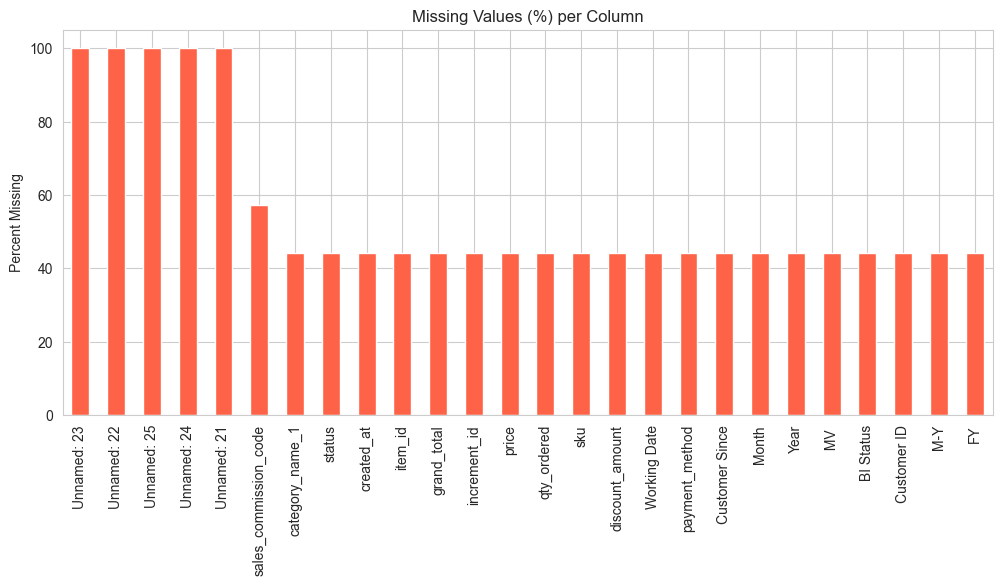

In [24]:
plt.figure(figsize=(12, 5))
missing_percent.plot(kind="bar", color="tomato")
plt.title("Missing Values (%) per Column")
plt.ylabel("Percent Missing")
plt.show()

**🔍 Observation:** Some columns (named `Unnamed: ...`) are almost 100% empty — they are junk columns.
Also, many rows at the bottom of the file are completely empty.

### 4.6 How many rows are completely empty?

In [25]:
empty_rows = df.isnull().all(axis=1).sum()
print("Completely empty rows:", empty_rows)

Completely empty rows: 464051


### 4.7 Duplicate rows

In [26]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 464050


### 4.8 Hidden missing values

This dataset uses the text `\N` to mean *missing*. Pandas does not see it as NaN, so let's count it.

In [27]:
hidden_missing = (df == "\\N").sum()
hidden_missing[hidden_missing > 0]

status                        4
category_name_1            7850
sales_commission_code    339001
dtype: int64

### 4.9 Unique values in each column

In [28]:
df.nunique()

item_id                  584524
status                       16
created_at                  789
sku                       84889
price                      9121
qty_ordered                  74
grand_total               36829
increment_id             408785
category_name_1              16
sales_commission_code      7225
discount_amount           28058
payment_method               18
Working Date                789
BI Status                     4
 MV                        9720
Year                          3
Month                        12
Customer Since               26
M-Y                          26
FY                            3
Customer ID              115326
Unnamed: 21                   0
Unnamed: 22                   0
Unnamed: 23                   0
Unnamed: 24                   0
Unnamed: 25                   0
dtype: int64

---
## Part 5 — Data Cleaning
We fix problems one by one. Each step has a reason.

### 5.1 Remove the junk `Unnamed` columns

In [29]:
unnamed_cols = [col for col in df.columns if "Unnamed" in col]
print(unnamed_cols)

['Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25']


In [30]:
df = df.drop(columns=unnamed_cols)

### 5.2 Remove rows that are completely empty

In [31]:
df = df.dropna(how="all")
print("Rows now:", df.shape[0])

Rows now: 584524


### 5.3 Clean column names (remove spaces, make lowercase)

In [32]:
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_").str.replace("-", "_")
df.columns.tolist()

['item_id',
 'status',
 'created_at',
 'sku',
 'price',
 'qty_ordered',
 'grand_total',
 'increment_id',
 'category_name_1',
 'sales_commission_code',
 'discount_amount',
 'payment_method',
 'working_date',
 'bi_status',
 'mv',
 'year',
 'month',
 'customer_since',
 'm_y',
 'fy',
 'customer_id']

### 5.4 Convert hidden missing `\N` into real NaN

In [33]:
df = df.replace("\\N", np.nan)

### 5.5 Fix the `mv` column

`mv` (money value) is stored as text like `' 1,950 '`. We remove commas and spaces and convert it to a number.

In [34]:
df["mv"].head()

0     1,950 
1       240 
2     2,450 
3       360 
4     1,110 
Name: mv, dtype: object

In [35]:
df["mv"] = df["mv"].astype(str).str.replace(",", "").str.strip()
df["mv"] = pd.to_numeric(df["mv"], errors="coerce")

In [36]:
df["mv"].head()

0    1950.0
1     240.0
2    2450.0
3     360.0
4    1110.0
Name: mv, dtype: float64

### 5.6 Convert date columns to real dates

In [37]:
df["created_at"] = pd.to_datetime(df["created_at"], errors="coerce")
df["working_date"] = pd.to_datetime(df["working_date"], errors="coerce")

In [38]:
df[["created_at", "working_date"]].head()

,created_at,working_date
0,2016-07-01,2016-07-01
1,2016-07-01,2016-07-01
2,2016-07-01,2016-07-01
3,2016-07-01,2016-07-01
4,2016-07-01,2016-07-01


### 5.7 Missing values after the first cleanup

In [39]:
(df.isnull().sum() / len(df) * 100).round(2).sort_values(ascending=False)

sales_commission_code    81.46
category_name_1           1.37
mv                        0.38
status                    0.00
item_id                   0.00
price                     0.00
sku                       0.00
created_at                0.00
grand_total               0.00
increment_id              0.00
discount_amount           0.00
payment_method            0.00
qty_ordered               0.00
working_date              0.00
bi_status                 0.00
year                      0.00
month                     0.00
customer_since            0.00
m_y                       0.00
fy                        0.00
customer_id               0.00
dtype: float64

### 5.8 Plan for filling missing values

| Column | Problem | Approach | Why |
|---|---|---|---|
| `sales_commission_code` | Mostly missing | **Drop column** | Too much missing, not useful |
| `customer_id` | Few missing | **Drop those rows** | Clustering is per customer, we cannot guess an ID |
| `status` | Few missing | Fill with **mode** (most common) | Categorical column |
| `category_name_1` | Some missing | Fill with **"Unknown"** | Keeps rows, honest label |
| `sku` | Few missing | Fill with **"Unknown"** | Product code cannot be guessed |
| `payment_method` | Few missing (if any) | Fill with **mode** | Categorical column |
| `price`, `grand_total`, `discount_amount` | Few missing | Fill with **median** | Median is not affected by outliers |
| `customer_since` | Few missing | Fill with **mode** | Categorical (Year-Month text) |

### 5.9 Drop `sales_commission_code` (too many missing)

In [40]:
print("Missing %:", round(df["sales_commission_code"].isnull().mean() * 100, 2))

Missing %: 81.46


In [41]:
df = df.drop(columns=["sales_commission_code"])

### 5.10 Drop rows with no `customer_id`

In [42]:
print("Rows without customer_id:", df["customer_id"].isnull().sum())

Rows without customer_id: 11


In [43]:
df = df.dropna(subset=["customer_id"])

### 5.11 Fill `status` with the most common value (mode)

In [44]:
status_mode = df["status"].mode()[0]
print("Most common status:", status_mode)

Most common status: complete


In [45]:
df["status"] = df["status"].fillna(status_mode)

### 5.12 Fill `category_name_1` and `sku` with 'Unknown'

In [46]:
df["category_name_1"] = df["category_name_1"].fillna("Unknown")

In [47]:
df["sku"] = df["sku"].fillna("Unknown")

### 5.13 Fill `payment_method` with mode

In [48]:
df["payment_method"] = df["payment_method"].fillna(df["payment_method"].mode()[0])

### 5.14 Fill numeric columns with median

In [49]:
numeric_cols = ["price", "qty_ordered", "grand_total", "discount_amount", "mv"]

In [50]:
for col in numeric_cols:
    median_value = df[col].median()
    df[col] = df[col].fillna(median_value)

### 5.15 Fill `customer_since` with mode

In [51]:
df["customer_since"] = df["customer_since"].fillna(df["customer_since"].mode()[0])

### 5.16 Drop any row where the order date could not be read

In [52]:
print("Rows without a valid date:", df["created_at"].isnull().sum())

Rows without a valid date: 0


In [53]:
df = df.dropna(subset=["created_at"])

### 5.17 Remove duplicate rows

In [54]:
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()

Duplicates: 0


### 5.18 Fix data types

In [55]:
df["customer_id"] = df["customer_id"].astype(int)
df["qty_ordered"] = df["qty_ordered"].astype(int)

### 5.19 Remove impossible values (negative price or quantity)

In [56]:
print("Negative price rows:", (df["price"] < 0).sum())
print("Zero/negative qty rows:", (df["qty_ordered"] <= 0).sum())

Negative price rows: 0
Zero/negative qty rows: 0


In [57]:
df = df[df["price"] >= 0]
df = df[df["qty_ordered"] > 0]

### 5.20 Final check — no missing values should remain

In [58]:
df.isnull().sum()

item_id            0
status             0
created_at         0
sku                0
price              0
qty_ordered        0
grand_total        0
increment_id       0
category_name_1    0
discount_amount    0
payment_method     0
working_date       0
bi_status          0
mv                 0
year               0
month              0
customer_since     0
m_y                0
fy                 0
customer_id        0
dtype: int64

In [59]:
print("Rows before cleaning:", df_raw.shape[0])
print("Rows after cleaning :", df.shape[0])

Rows before cleaning: 1048575
Rows after cleaning : 584513


---
## Part 6 — Create Helper Columns for Analysis

Extract year, month and weekday from the order date.

In [60]:
df["order_year"] = df["created_at"].dt.year
df["order_month"] = df["created_at"].dt.month
df["order_weekday"] = df["created_at"].dt.day_name()
df["year_month"] = df["created_at"].dt.to_period("M").astype(str)

Look at all order statuses.

In [61]:
df["status"].value_counts()

status
complete          233704
canceled          201244
received           77289
order_refunded     59524
refund              8050
cod                 2859
paid                1159
closed               494
payment_review        57
pending               48
processing            33
holded                31
fraud                 10
pending_paypal         7
exchange               4
Name: count, dtype: int64

There are many statuses. Let's group them into 4 simple groups.

In [62]:
def group_status(s):
    if s in ["complete", "received", "closed", "paid", "cod", "exchange"]:
        return "Completed"
    elif s in ["canceled", "fraud"]:
        return "Canceled"
    elif s in ["order_refunded", "refund"]:
        return "Refunded"
    else:
        return "Other"

In [63]:
df["status_group"] = df["status"].apply(group_status)
df["status_group"].value_counts()

status_group
Completed    315509
Canceled     201254
Refunded      67574
Other           176
Name: count, dtype: int64

---
## Part 7 — Exploratory Data Analysis (EDA)
We look at the data from many angles: **statistics, orders, categories, payments, time, money and customers.**

### 7.1 Statistical summary of numeric columns

In [64]:
df[numeric_cols].describe().round(2)

,price,qty_ordered,grand_total,discount_amount,mv
count,584513.00,584513.0,584513.00,584513.00,584513.00
mean,6348.82,1.3,8530.68,499.50,7181.16
std,14949.40,4.0,61321.38,1506.96,33946.89
min,0.00,1.0,-1594.00,-599.50,0.00
25%,360.00,1.0,945.00,0.00,399.00
50%,899.00,1.0,1960.40,0.00,999.00
75%,4070.00,1.0,6999.00,160.52,5000.00
max,1012625.90,1000.0,17888000.00,90300.00,8944000.00


### 7.2 Summary of text (categorical) columns

In [65]:
df[["status", "category_name_1", "payment_method", "bi_status"]].describe()

,status,category_name_1,payment_method,bi_status
count,584513,584513,584513,584513
unique,15,16,18,4
top,complete,Mobiles & Tablets,cod,Net
freq,233704,115710,271955,234178


### 7.3 Order Status

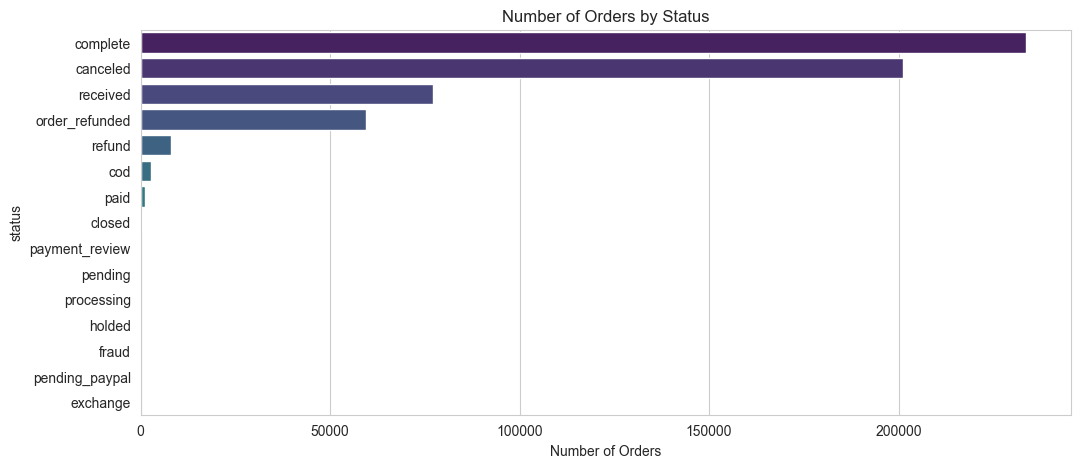

In [66]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, y="status", order=df["status"].value_counts().index, palette="viridis")
plt.title("Number of Orders by Status")
plt.xlabel("Number of Orders")
plt.show()

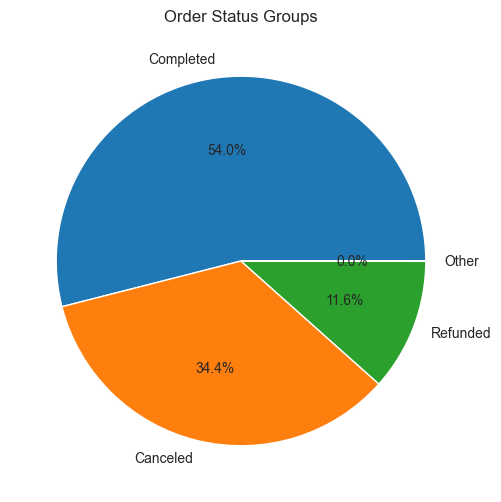

In [67]:
df["status_group"].value_counts().plot(kind="pie", autopct="%1.1f%%", figsize=(6, 6))
plt.title("Order Status Groups")
plt.ylabel("")
plt.show()

**🔍 Insight:** A large share of orders get canceled — a big business problem worth studying.

### 7.4 Product Categories

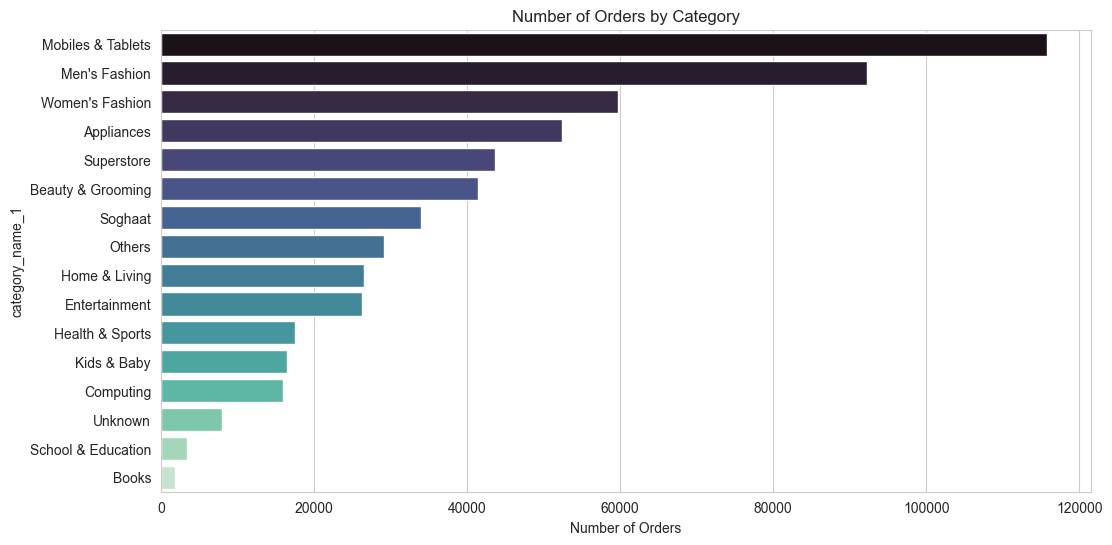

In [68]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, y="category_name_1", order=df["category_name_1"].value_counts().index, palette="mako")
plt.title("Number of Orders by Category")
plt.xlabel("Number of Orders")
plt.show()

Which category brings the most **revenue**?

In [69]:
category_revenue = df.groupby("category_name_1")["grand_total"].sum().sort_values(ascending=False)
category_revenue

category_name_1
Mobiles & Tablets     2.440791e+09
Appliances            6.568497e+08
Entertainment         5.390480e+08
Women's Fashion       2.825768e+08
Computing             2.025457e+08
Men's Fashion         1.941368e+08
Others                1.924106e+08
Superstore            1.121309e+08
Beauty & Grooming     9.718359e+07
Home & Living         8.821708e+07
Kids & Baby           4.723743e+07
Soghaat               4.634325e+07
Health & Sports       4.179475e+07
Unknown               3.611236e+07
School & Education    6.237084e+06
Books                 2.676195e+06
Name: grand_total, dtype: float64

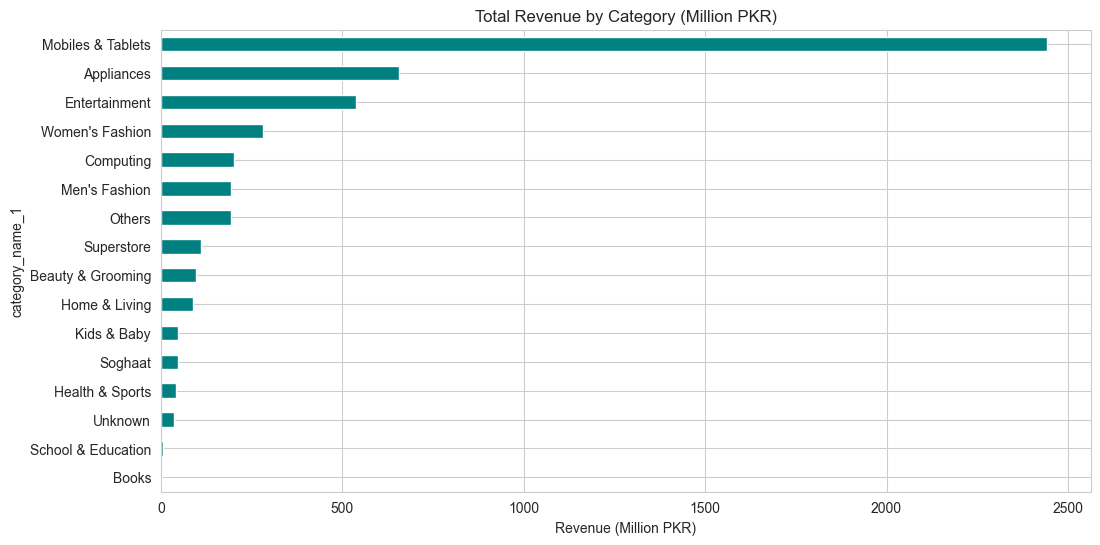

In [70]:
plt.figure(figsize=(12, 6))
(category_revenue / 1_000_000).plot(kind="barh", color="teal")
plt.title("Total Revenue by Category (Million PKR)")
plt.xlabel("Revenue (Million PKR)")
plt.gca().invert_yaxis()
plt.show()

Average item price per category.

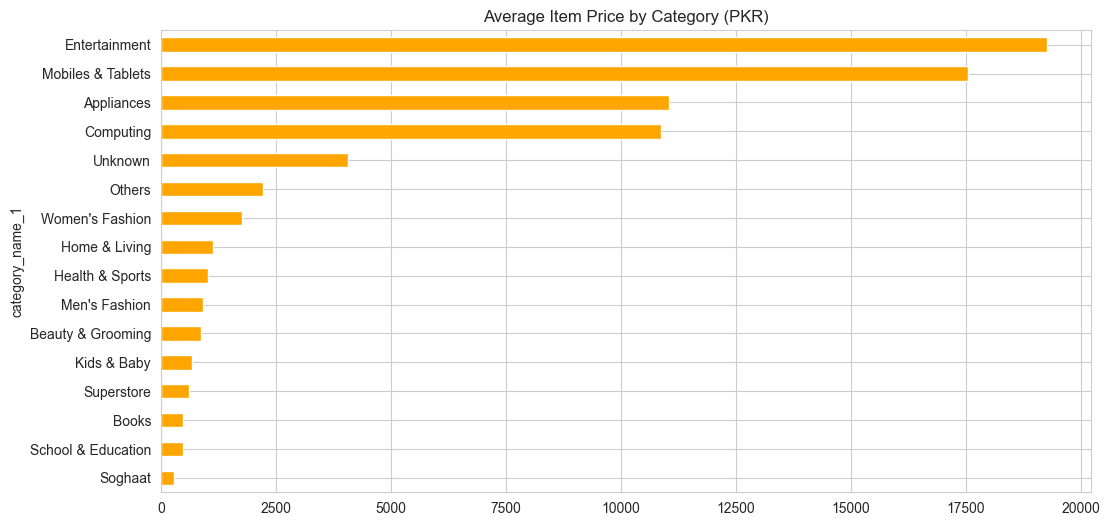

In [71]:
avg_price = df.groupby("category_name_1")["price"].mean().sort_values(ascending=False)
plt.figure(figsize=(12, 6))
avg_price.plot(kind="barh", color="orange")
plt.title("Average Item Price by Category (PKR)")
plt.gca().invert_yaxis()
plt.show()

Cancel rate in each category.

In [72]:
cancel_rate = df.groupby("category_name_1")["status_group"].apply(lambda x: (x == "Canceled").mean() * 100)
cancel_rate = cancel_rate.sort_values(ascending=False)

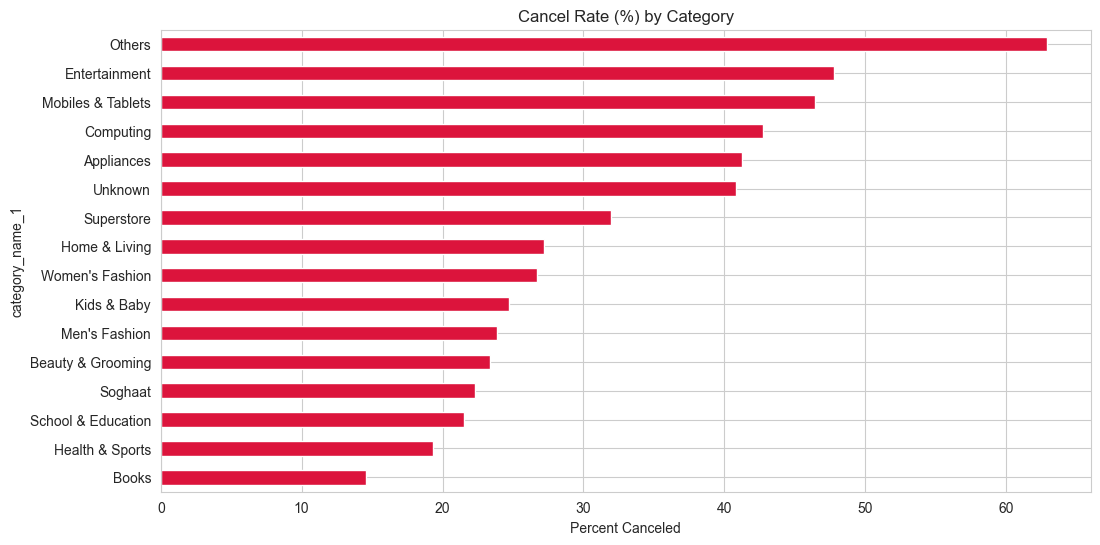

In [73]:
plt.figure(figsize=(12, 6))
cancel_rate.plot(kind="barh", color="crimson")
plt.title("Cancel Rate (%) by Category")
plt.xlabel("Percent Canceled")
plt.gca().invert_yaxis()
plt.show()

### 7.5 Payment Methods

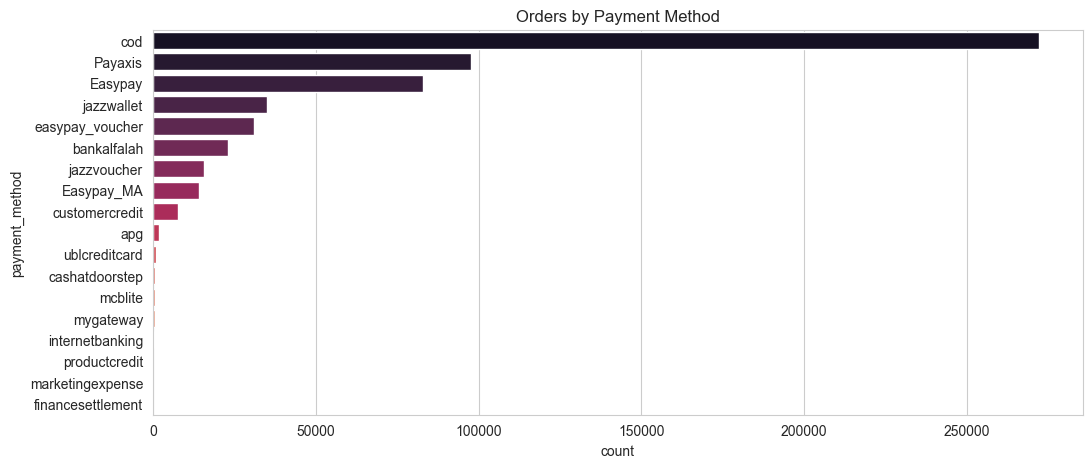

In [74]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, y="payment_method", order=df["payment_method"].value_counts().index, palette="rocket")
plt.title("Orders by Payment Method")
plt.show()

Which payment methods get canceled most? (row percentages)

In [75]:
pay_status = pd.crosstab(df["payment_method"], df["status_group"], normalize="index") * 100
pay_status.round(1)

status_group,Canceled,Completed,Other,Refunded
payment_method,,,,
Easypay,62.8,33.2,0.0,4.0
Easypay_MA,65.7,31.1,0.0,3.3
Payaxis,62.8,32.8,0.0,4.5
apg,77.4,20.0,0.0,2.6
bankalfalah,70.2,25.8,0.3,3.7
cashatdoorstep,0.7,92.8,0.0,6.6
cod,8.0,72.0,0.0,20.0
customercredit,0.6,79.6,0.0,19.7
easypay_voucher,39.1,58.5,0.1,2.3


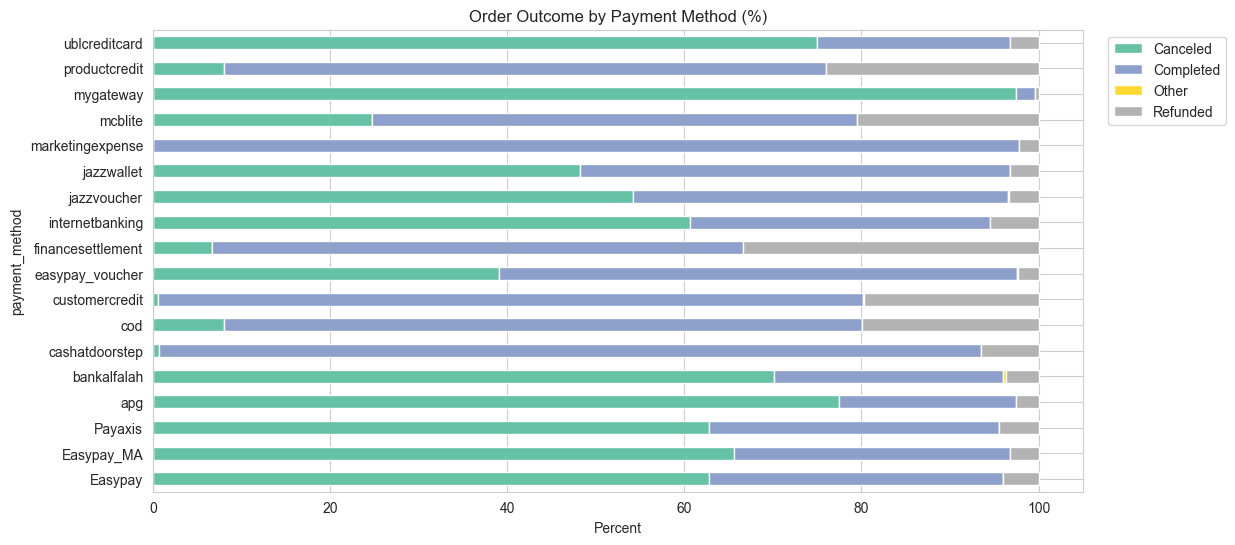

In [76]:
pay_status.plot(kind="barh", stacked=True, figsize=(12, 6), colormap="Set2")
plt.title("Order Outcome by Payment Method (%)")
plt.xlabel("Percent")
plt.legend(bbox_to_anchor=(1.02, 1))
plt.show()

### 7.6 Sales Over Time

In [77]:
monthly_orders = df.groupby("year_month")["increment_id"].nunique()

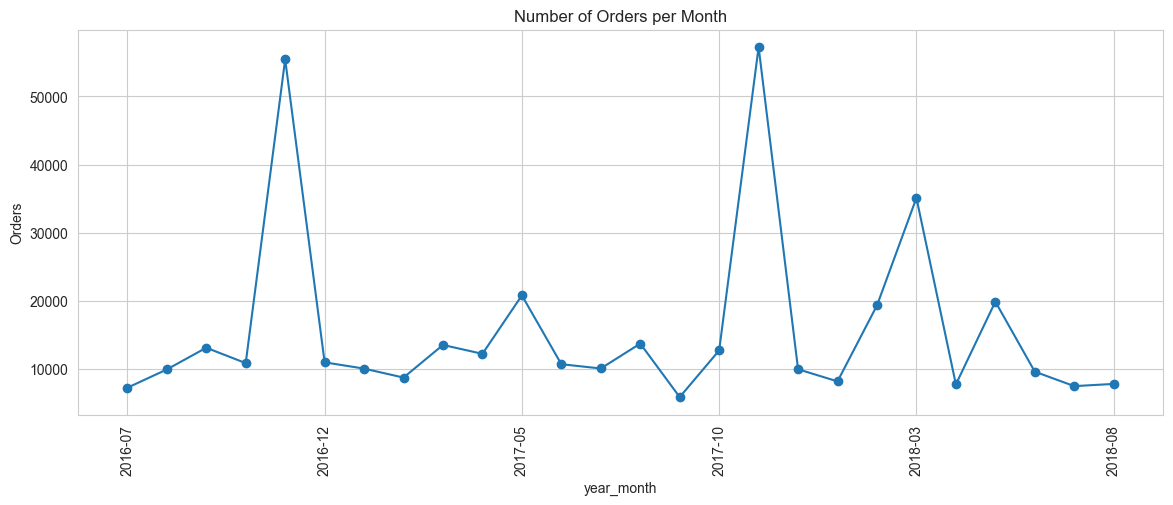

In [78]:
plt.figure(figsize=(14, 5))
monthly_orders.plot(marker="o")
plt.title("Number of Orders per Month")
plt.ylabel("Orders")
plt.xticks(rotation=90)
plt.show()

In [79]:
monthly_revenue = df.groupby("year_month")["grand_total"].sum() / 1_000_000

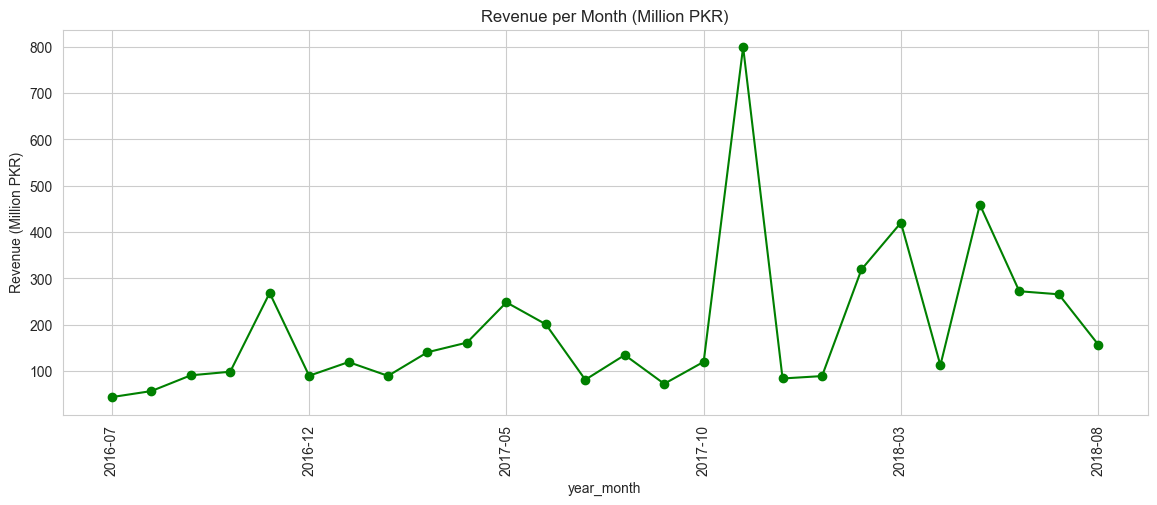

In [80]:
plt.figure(figsize=(14, 5))
monthly_revenue.plot(marker="o", color="green")
plt.title("Revenue per Month (Million PKR)")
plt.ylabel("Revenue (Million PKR)")
plt.xticks(rotation=90)
plt.show()

**🔍 Insight:** Look for big spikes — usually sale events like **11.11** and **Black Friday (November)**.

Orders by year.

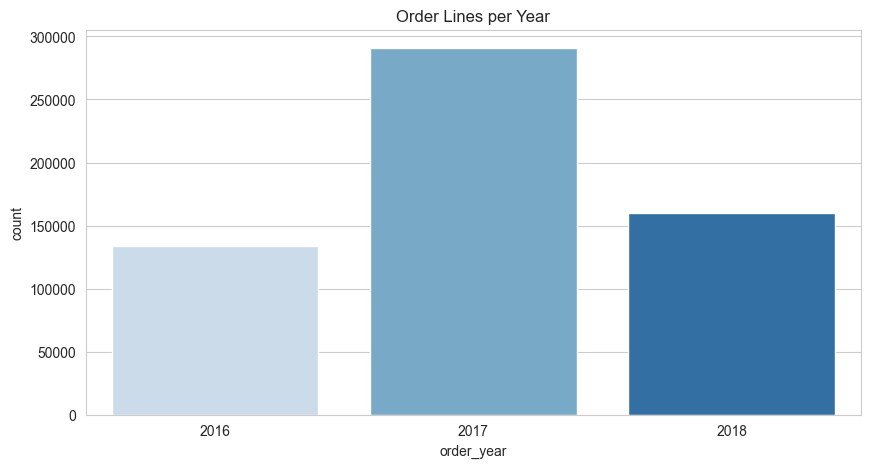

In [81]:
sns.countplot(data=df, x="order_year", palette="Blues")
plt.title("Order Lines per Year")
plt.show()

Orders by day of the week.

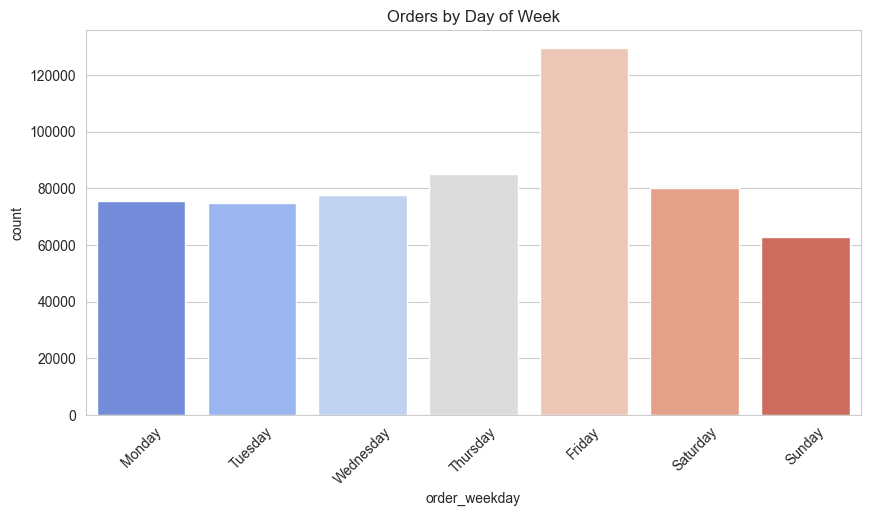

In [82]:
week_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
sns.countplot(data=df, x="order_weekday", order=week_order, palette="coolwarm")
plt.title("Orders by Day of Week")
plt.xticks(rotation=45)
plt.show()

Heatmap: orders by month and year.

In [83]:
month_year = pd.crosstab(df["order_month"], df["order_year"])

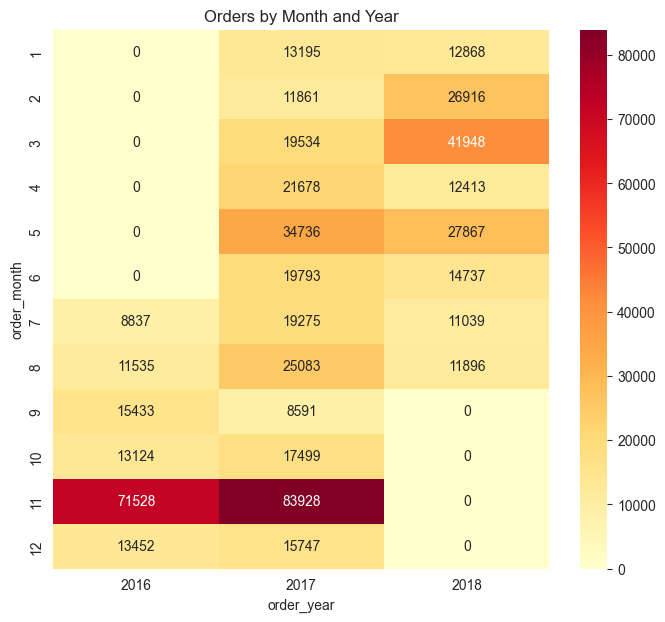

In [84]:
plt.figure(figsize=(8, 7))
sns.heatmap(month_year, annot=True, fmt="d", cmap="YlOrRd")
plt.title("Orders by Month and Year")
plt.show()

### 7.7 Money Columns — Distributions and Outliers

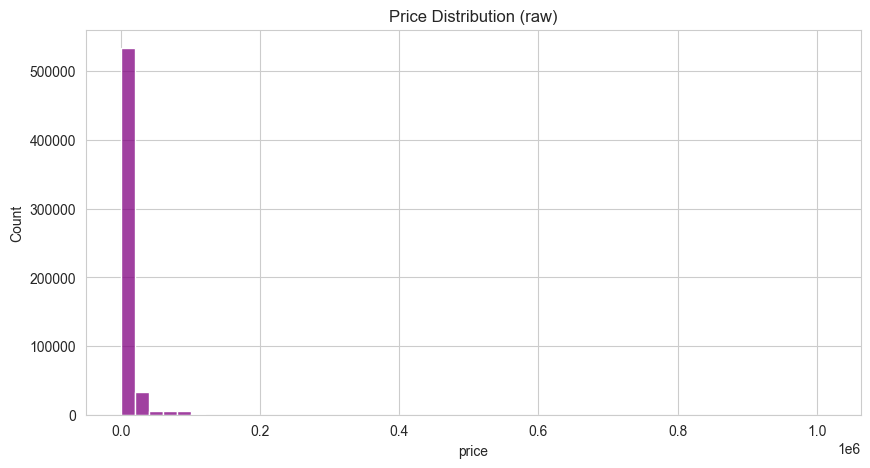

In [85]:
sns.histplot(df["price"], bins=50, color="purple")
plt.title("Price Distribution (raw)")
plt.show()

The data is very **skewed** (a few very expensive items). A log scale shows it better.

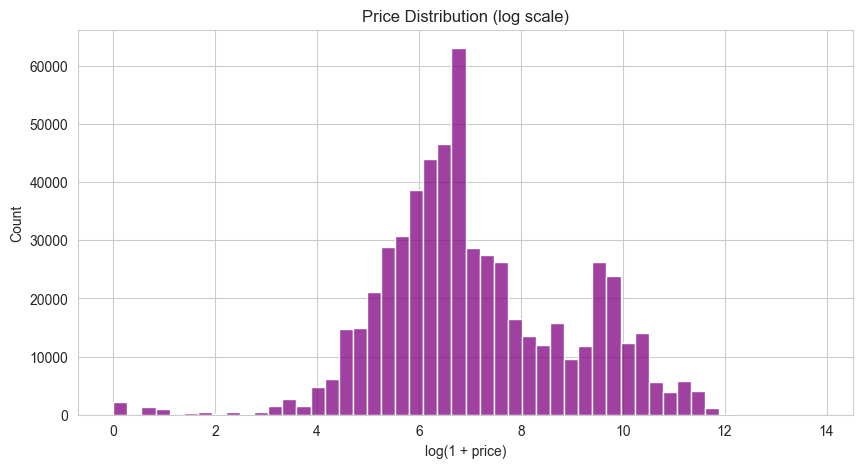

In [86]:
sns.histplot(np.log1p(df["price"]), bins=50, color="purple")
plt.title("Price Distribution (log scale)")
plt.xlabel("log(1 + price)")
plt.show()

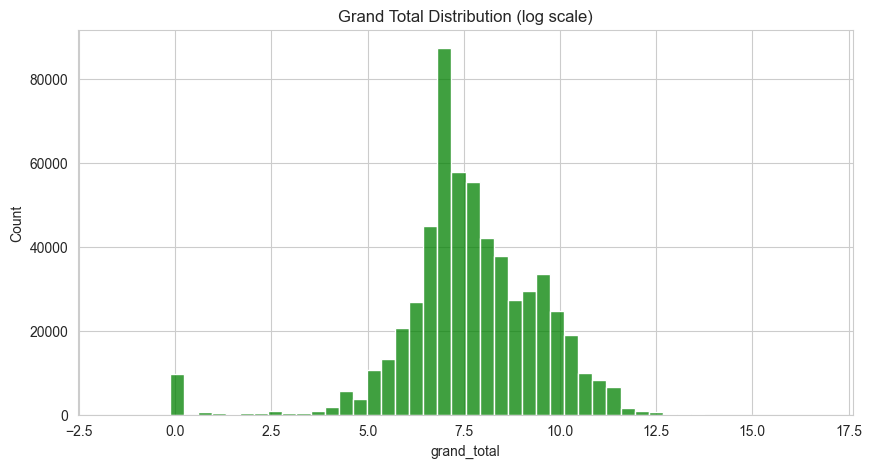

In [87]:
sns.histplot(np.log1p(df["grand_total"]), bins=50, color="green")
plt.title("Grand Total Distribution (log scale)")
plt.show()

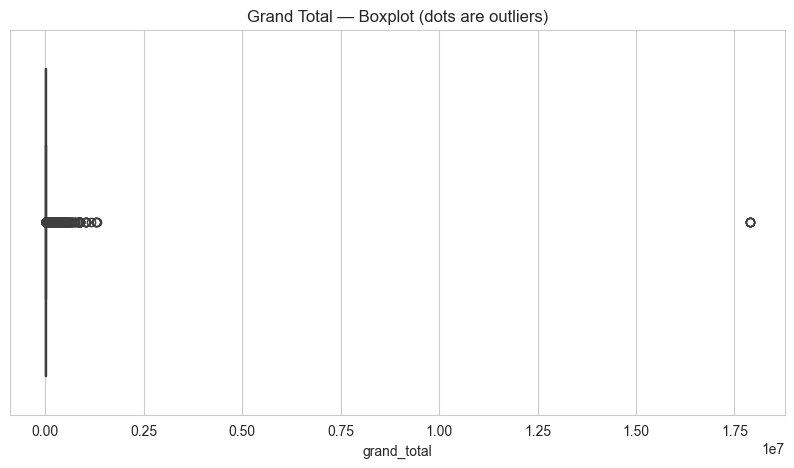

In [88]:
sns.boxplot(x=df["grand_total"])
plt.title("Grand Total — Boxplot (dots are outliers)")
plt.show()

How many orders got a discount?

In [89]:
has_discount = (df["discount_amount"] > 0).mean() * 100
print(f"Orders with discount: {has_discount:.1f}%")

Orders with discount: 35.6%


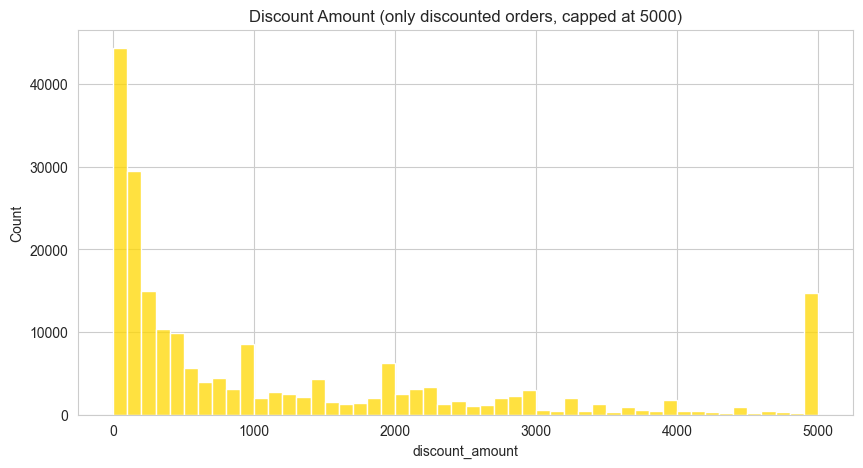

In [90]:
sns.histplot(df.loc[df["discount_amount"] > 0, "discount_amount"].clip(upper=5000), bins=50, color="gold")
plt.title("Discount Amount (only discounted orders, capped at 5000)")
plt.show()

Quantity per order line.

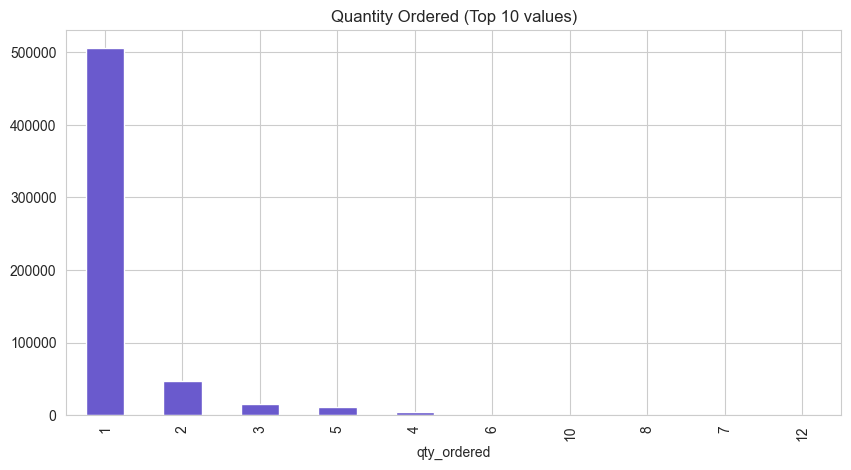

In [91]:
df["qty_ordered"].value_counts().head(10).plot(kind="bar", color="slateblue")
plt.title("Quantity Ordered (Top 10 values)")
plt.show()

### 7.8 Correlation Between Numeric Columns

In [92]:
corr = df[numeric_cols].corr()

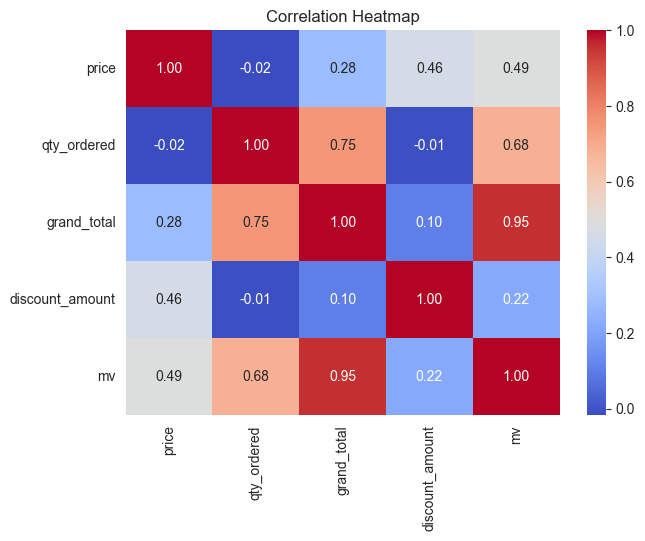

In [93]:
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

### 7.9 Customers

In [94]:
print("Unique customers:", df["customer_id"].nunique())
print("Unique orders   :", df["increment_id"].nunique())

Unique customers: 115326
Unique orders   : 408776


In [95]:
orders_per_customer = df.groupby("customer_id")["increment_id"].nunique()
orders_per_customer.describe()

count    115326.000000
mean          3.544526
std          17.718028
min           1.000000
25%           1.000000
50%           1.000000
75%           3.000000
max        2107.000000
Name: increment_id, dtype: float64

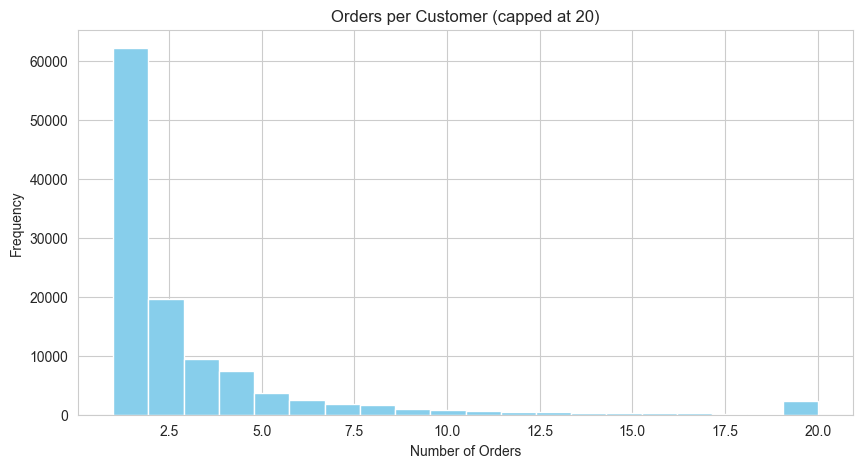

In [96]:
orders_per_customer.clip(upper=20).plot(kind="hist", bins=20, color="skyblue")
plt.title("Orders per Customer (capped at 20)")
plt.xlabel("Number of Orders")
plt.show()

**🔍 Insight:** Most customers buy only once or twice — a few loyal customers buy a lot. That is exactly what clustering will help us find.

---
## Part 8 — Build Customer Features for Clustering (RFM)

K-Means needs **one row per customer**. We use the famous **RFM** idea:

- **Recency** → how many days since the customer's last order (smaller = better)
- **Frequency** → how many orders the customer made
- **Monetary** → how much money the customer spent

We also add **average order value**, **total quantity** and **total discount**.

> We use only **completed** orders, because canceled orders are not real purchases.

In [97]:
completed = df[df["status_group"] == "Completed"]
print("Completed order lines:", completed.shape[0])

Completed order lines: 315509


Reference date = one day after the last order in the data.

In [98]:
reference_date = completed["created_at"].max() + pd.Timedelta(days=1)
print(reference_date)

2018-08-29 00:00:00


In [99]:
customers = completed.groupby("customer_id").agg(
    last_order=("created_at", "max"),
    frequency=("increment_id", "nunique"),
    monetary=("grand_total", "sum"),
    total_qty=("qty_ordered", "sum"),
    total_discount=("discount_amount", "sum")
)

In [100]:
customers["recency"] = (reference_date - customers["last_order"]).dt.days

In [101]:
customers["avg_order_value"] = customers["monetary"] / customers["frequency"]

In [102]:
customers = customers.drop(columns=["last_order"])
customers.head()

,frequency,monetary,total_qty,total_discount,recency,avg_order_value
customer_id,,,,,,
1,1,1950.00,1,0.00,789,1950.000000
3,1,4980.00,4,0.00,467,4980.000000
4,236,1316173.25,313,156739.25,2,5577.005297
6,1,170.00,1,0.00,789,170.000000
7,4,105.00,4,1864.00,501,26.250000


In [103]:
print("Number of customers:", customers.shape[0])

Number of customers: 80128


In [104]:
customers.describe().round(2)

,frequency,monetary,total_qty,total_discount,recency,avg_order_value
count,80128.00,80128.00,80128.00,80128.00,80128.00,80128.00
mean,2.58,20369.56,4.93,1880.14,367.65,7690.95
std,14.07,151853.24,26.94,8440.33,207.26,128567.54
min,1.00,0.00,1.00,0.00,1.00,0.00
25%,1.00,1050.00,1.00,0.00,186.00,912.00
50%,1.00,3249.00,2.00,0.00,314.00,2286.83
75%,2.00,13117.65,4.00,253.50,550.00,7240.50
max,1665.00,35776000.00,3247.00,433566.26,789.00,35776000.00


Check: any missing values in the customer table?

In [105]:
customers.isnull().sum()

frequency          0
monetary           0
total_qty          0
total_discount     0
recency            0
avg_order_value    0
dtype: int64

Remove customers who spent 0 (they would confuse the model).

In [106]:
customers = customers[customers["monetary"] > 0]

---
## Part 9 — Make the Data Reliable for K-Means

K-Means uses **distance**. So it is sensitive to:
1. **Outliers** — one huge customer can pull a whole cluster
2. **Skewed data** — most values small, a few very large
3. **Different scales** — money in thousands vs. frequency in single digits

We fix each problem one by one.

In [107]:
features = ["recency", "frequency", "monetary", "avg_order_value", "total_qty", "total_discount"]

### 9.1 Look at the distributions before fixing

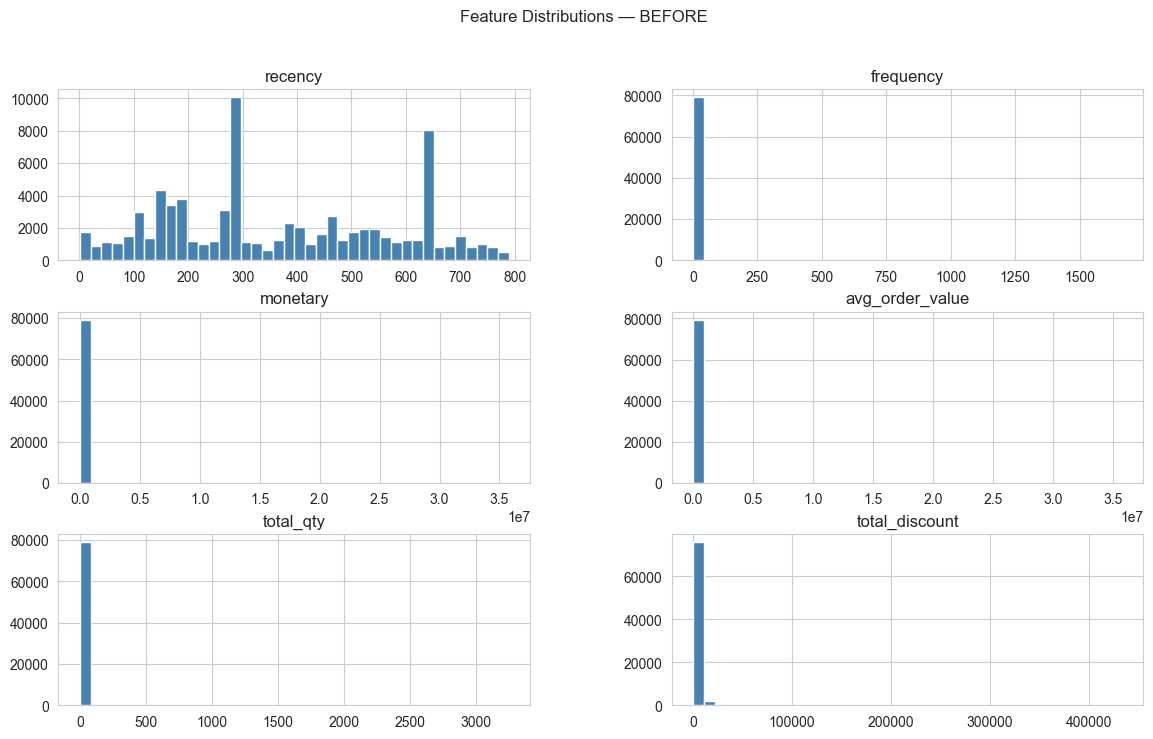

In [108]:
customers[features].hist(bins=40, figsize=(14, 8), color="steelblue")
plt.suptitle("Feature Distributions — BEFORE")
plt.show()

### 9.2 Cap outliers (IQR method)

Values above `Q3 + 1.5 × IQR` are pulled down to that limit. We **cap** instead of delete, so we keep every customer.

In [109]:
X = customers[features].copy()

In [110]:
for col in features:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    X[col] = X[col].clip(lower=lower, upper=upper)

> Note: `frequency` and `total_discount` can become constant after IQR capping (most customers have 1 order / 0 discount). We check this next.

In [111]:
X.nunique()

recency              788
frequency              4
monetary           19109
avg_order_value    23513
total_qty              9
total_discount      2204
dtype: int64

If a column has only 1 unique value now, it carries no information. To keep that information we use the **99th percentile** cap for those columns instead.

In [112]:
for col in features:
    if X[col].nunique() <= 1:
        upper = customers[col].quantile(0.99)
        X[col] = customers[col].clip(upper=upper)
        print("Used 99th percentile cap for:", col)

### 9.3 Log transform to reduce skew

In [113]:
X_log = np.log1p(X)

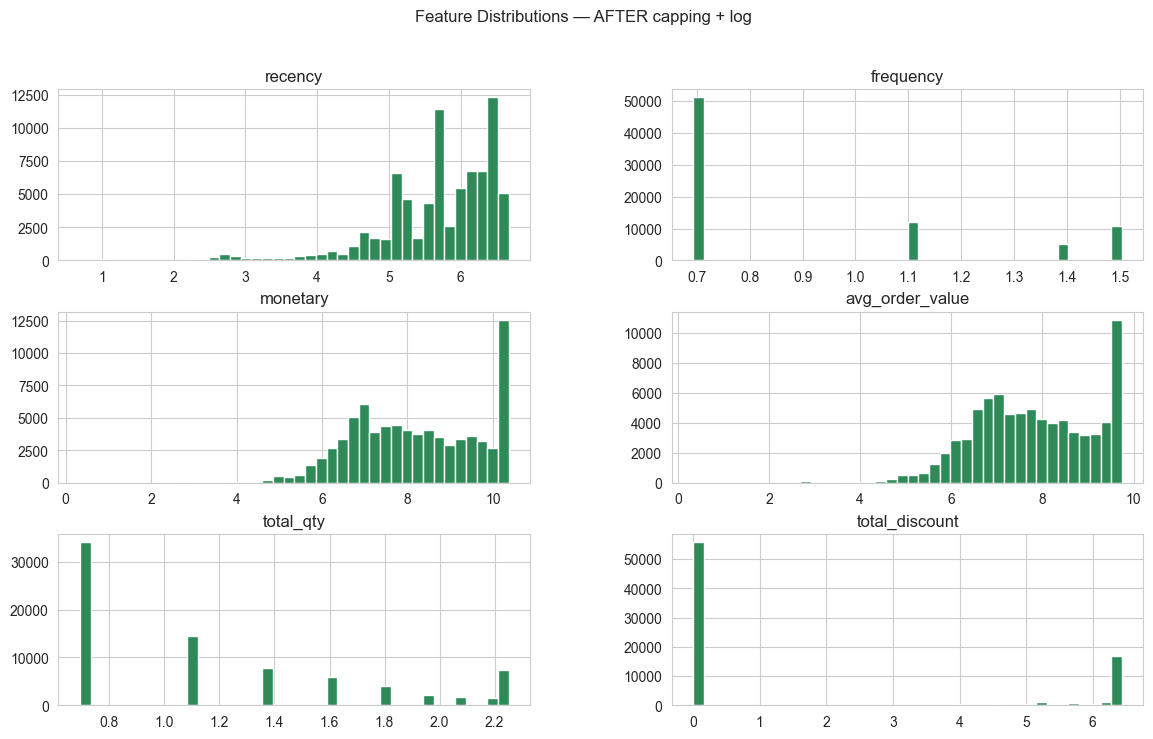

In [114]:
X_log.hist(bins=40, figsize=(14, 8), color="seagreen")
plt.suptitle("Feature Distributions — AFTER capping + log")
plt.show()

### 9.4 Scale features (mean = 0, std = 1)

In [115]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

In [116]:
X_scaled_df = pd.DataFrame(X_scaled, columns=features)
X_scaled_df.describe().round(2)

,recency,frequency,monetary,avg_order_value,total_qty,total_discount
count,79294.00,79294.00,79294.00,79294.00,79294.00,79294.00
mean,-0.00,0.00,-0.00,0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-5.97,-0.69,-5.27,-5.75,-0.92,-0.64
25%,-0.53,-0.69,-0.81,-0.73,-0.92,-0.64
50%,0.10,-0.69,-0.05,-0.04,-0.18,-0.64
75%,0.77,0.59,0.88,0.85,0.75,1.31
max,1.20,1.88,1.46,1.49,1.92,1.64


Check correlation between the final features.

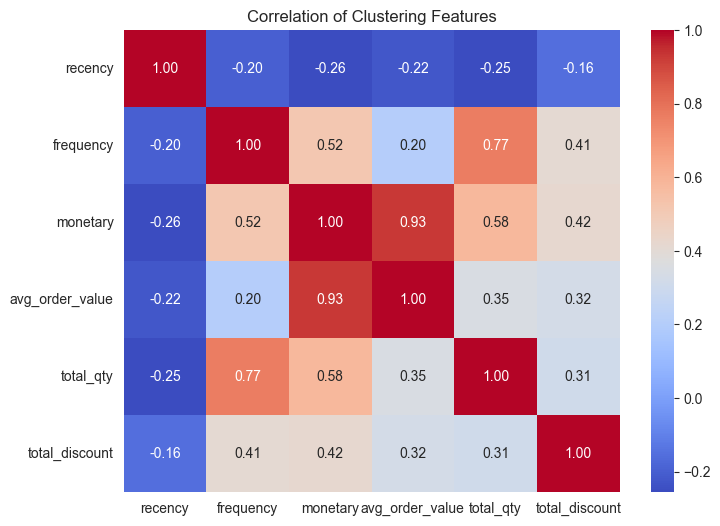

In [117]:
plt.figure(figsize=(8, 6))
sns.heatmap(X_scaled_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation of Clustering Features")
plt.show()

---
## Part 10 — K-Means Clustering

### 10.1 Elbow Method
We train K-Means for K = 2 to 10 and record the **inertia** (how tight the clusters are).
The best K is where the line bends like an **elbow**.

In [118]:
inertia = []
k_values = range(2, 11)

In [119]:
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)
    print("K =", k, "done")

K = 2 done
K = 3 done
K = 4 done
K = 5 done
K = 6 done
K = 7 done
K = 8 done
K = 9 done
K = 10 done


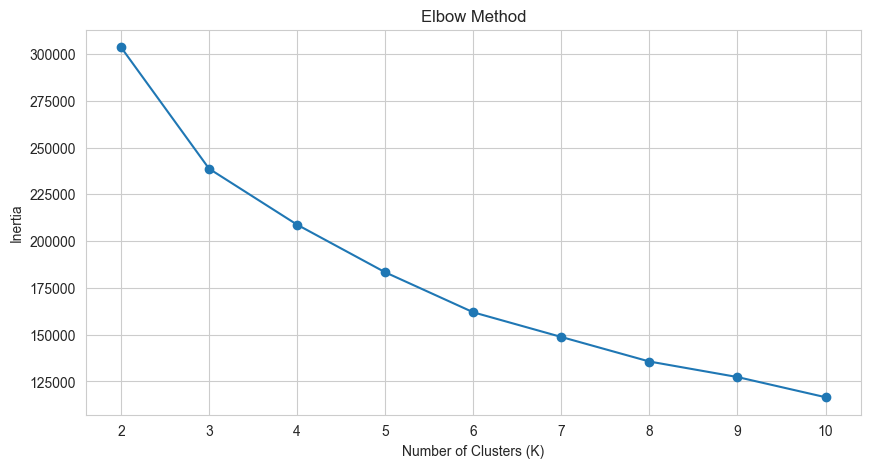

In [120]:
plt.plot(k_values, inertia, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.show()

### 10.2 Silhouette Score
Score between -1 and 1. **Higher = better separated clusters.**
Silhouette is slow on big data, so we calculate it on a random sample of 10,000 customers.

In [121]:
sample_size = min(10000, len(X_scaled))
np.random.seed(42)
sample_index = np.random.choice(len(X_scaled), sample_size, replace=False)
X_sample = X_scaled[sample_index]

In [122]:
sil_scores = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_sample)
    score = silhouette_score(X_sample, labels)
    sil_scores.append(score)
    print("K =", k, " Silhouette =", round(score, 3))

K = 2  Silhouette = 0.353
K = 3  Silhouette = 0.304
K = 4  Silhouette = 0.3
K = 5  Silhouette = 0.319
K = 6  Silhouette = 0.313
K = 7  Silhouette = 0.288
K = 8  Silhouette = 0.307
K = 9  Silhouette = 0.315
K = 10  Silhouette = 0.315


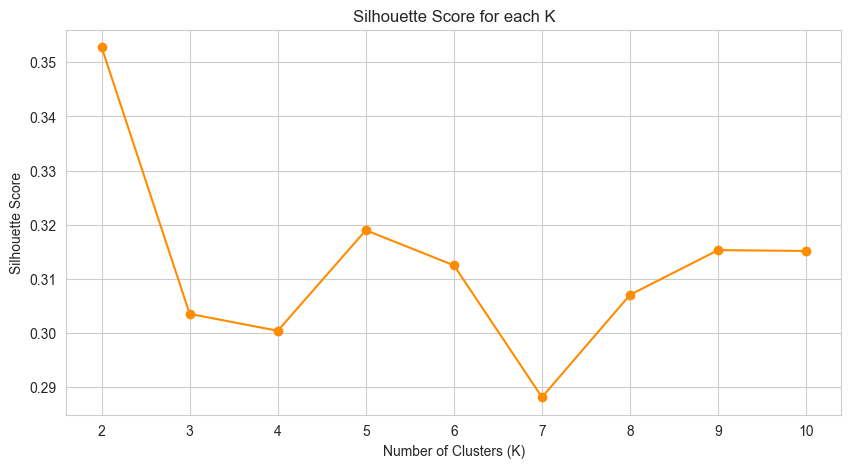

In [123]:
plt.plot(k_values, sil_scores, marker="o", color="darkorange")
plt.title("Silhouette Score for each K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.show()

### 10.3 Choose K
Look at both charts. Pick a K where the elbow bends **and** silhouette is good.
For customer segmentation, **K = 4** is usually a good, easy-to-explain choice.
👉 Change the number below if your charts suggest a different K.

In [124]:
best_k = 4

### 10.4 Train the final model

In [125]:
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans.fit(X_scaled)

KMeans(n_clusters=4, n_init=10, random_state=42)

In [126]:
customers["cluster"] = kmeans.labels_

In [127]:
customers["cluster"].value_counts().sort_index()

cluster
0    30764
1     9521
2    16954
3    22055
Name: count, dtype: int64

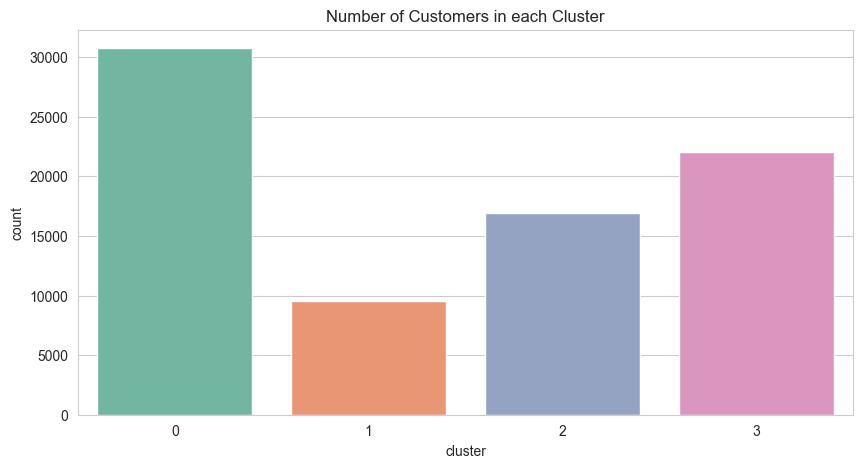

In [128]:
sns.countplot(data=customers, x="cluster", palette="Set2")
plt.title("Number of Customers in each Cluster")
plt.show()

---
## Part 11 — Understand the Clusters

### 11.1 Average values per cluster (original units)

In [129]:
cluster_profile = customers.groupby("cluster")[features].mean().round(1)
cluster_profile

,recency,frequency,monetary,avg_order_value,total_qty,total_discount
cluster,,,,,,
0,448.6,1.2,992.5,890.9,1.4,125.3
1,328.6,1.3,16415.9,13634.3,2.1,3010.3
2,266.6,7.7,67676.8,11074.7,15.9,6811.0
3,349.1,1.2,13509.4,12300.2,2.8,0.0


Add the cluster size.

In [130]:
cluster_profile["customers"] = customers["cluster"].value_counts().sort_index()
cluster_profile

,recency,frequency,monetary,avg_order_value,total_qty,total_discount,customers
cluster,,,,,,,
0,448.6,1.2,992.5,890.9,1.4,125.3,30764
1,328.6,1.3,16415.9,13634.3,2.1,3010.3,9521
2,266.6,7.7,67676.8,11074.7,15.9,6811.0,16954
3,349.1,1.2,13509.4,12300.2,2.8,0.0,22055


### 11.2 Heatmap of the cluster profile (scaled so colors are comparable)

In [131]:
profile_scaled = X_scaled_df.copy()
profile_scaled["cluster"] = kmeans.labels_
profile_scaled = profile_scaled.groupby("cluster").mean()

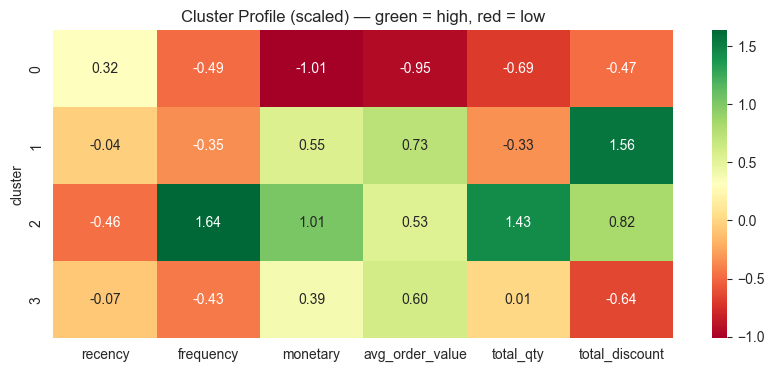

In [132]:
plt.figure(figsize=(10, 4))
sns.heatmap(profile_scaled, annot=True, cmap="RdYlGn", fmt=".2f")
plt.title("Cluster Profile (scaled) — green = high, red = low")
plt.show()

### 11.3 Boxplots of each feature by cluster

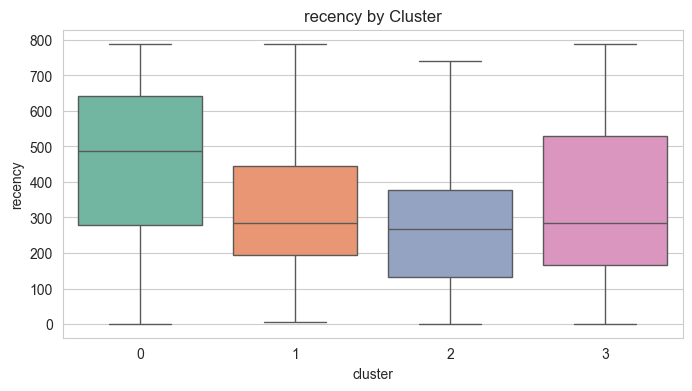

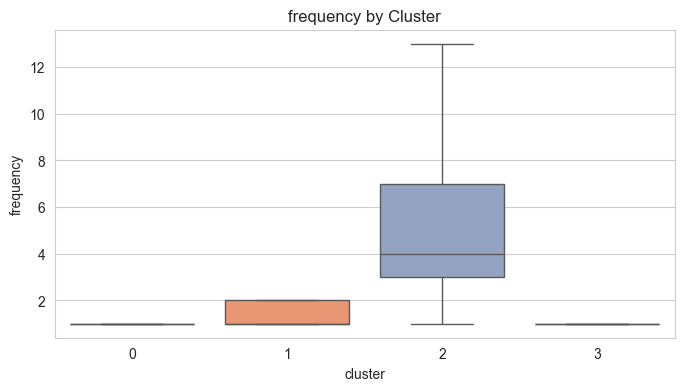

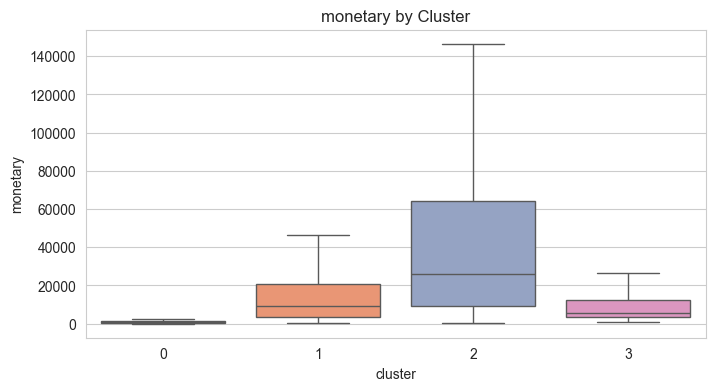

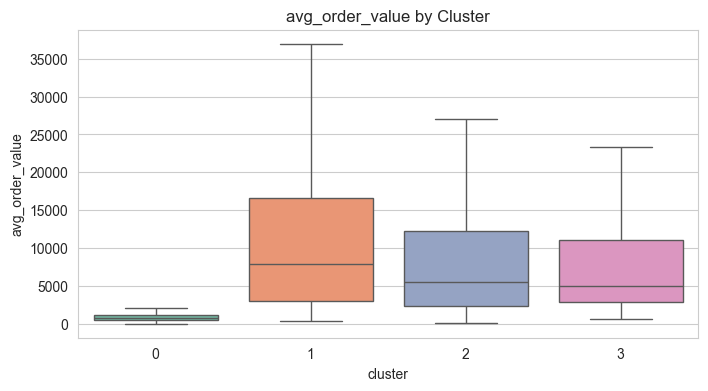

In [133]:
for col in ["recency", "frequency", "monetary", "avg_order_value"]:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=customers, x="cluster", y=col, palette="Set2", showfliers=False)
    plt.title(f"{col} by Cluster")
    plt.show()

### 11.4 Visualize clusters in 2D with PCA

PCA squeezes our 6 features into 2, so we can draw the clusters on a flat chart.

In [134]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

In [135]:
print("Variance explained by 2 components:", round(pca.explained_variance_ratio_.sum() * 100, 1), "%")

Variance explained by 2 components: 69.1 %


In [136]:
pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["cluster"] = kmeans.labels_

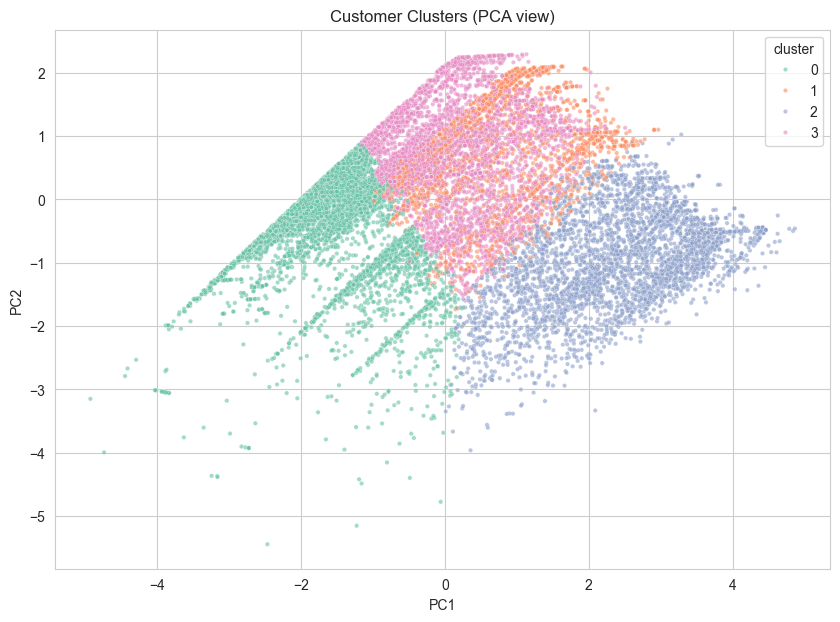

In [137]:
plt.figure(figsize=(10, 7))
sns.scatterplot(data=pca_df.sample(20000, random_state=42), x="PC1", y="PC2",
                hue="cluster", palette="Set2", s=10, alpha=0.6)
plt.title("Customer Clusters (PCA view)")
plt.show()

### 11.5 Recency vs Monetary scatter

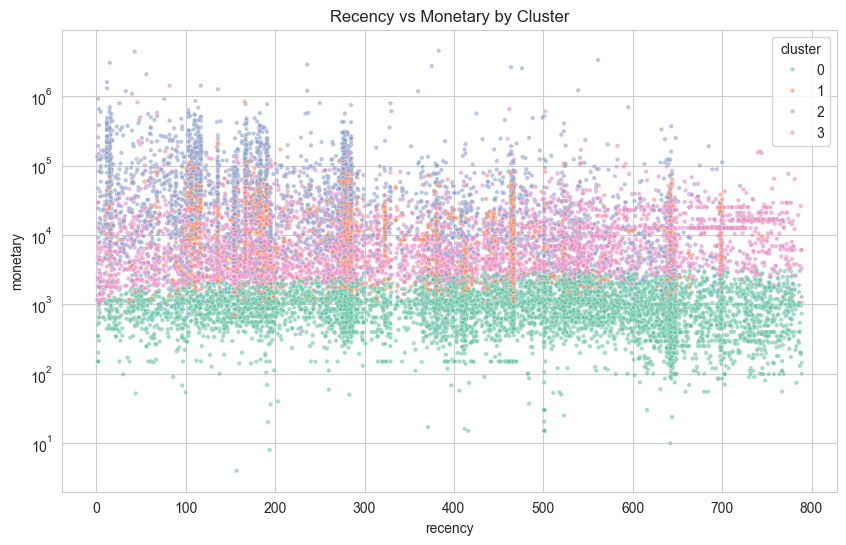

In [138]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=customers.sample(20000, random_state=42), x="recency", y="monetary",
                hue="cluster", palette="Set2", s=10, alpha=0.6)
plt.yscale("log")
plt.title("Recency vs Monetary by Cluster")
plt.show()

### 11.6 Give each cluster a business name
Look at the profile table above and name each cluster. Typical segments:

| Pattern | Name |
|---|---|
| Low recency, high frequency, high monetary | 🏆 **Champions / Loyal** |
| High avg order value, few orders | 💎 **Big Spenders** |
| Low recency, 1 order, low spend | 🌱 **New Customers** |
| High recency, low frequency, low spend | 😴 **Lost / Inactive** |

👉 Edit the dictionary below to match **your** results (cluster numbers can change between runs).

In [139]:
cluster_names = {
    0: "Cluster 0",
    1: "Cluster 1",
    2: "Cluster 2",
    3: "Cluster 3"
}

In [140]:
customers["segment"] = customers["cluster"].map(cluster_names)
customers["segment"].value_counts()

segment
Cluster 0    30764
Cluster 3    22055
Cluster 2    16954
Cluster 1     9521
Name: count, dtype: int64

Revenue share of each segment.

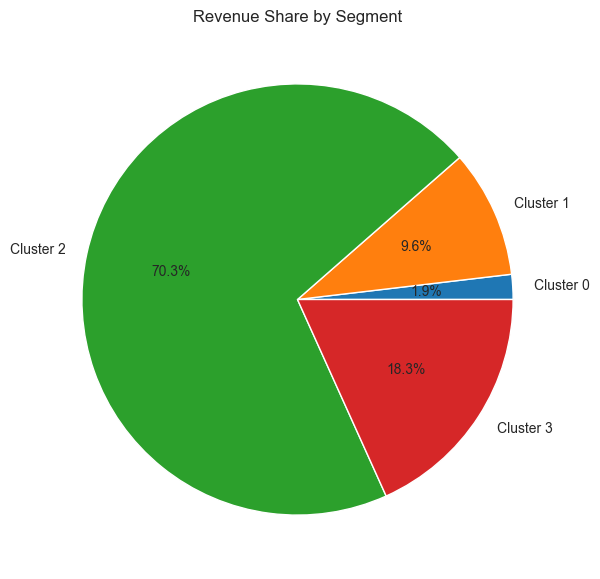

In [141]:
segment_revenue = customers.groupby("segment")["monetary"].sum()
segment_revenue.plot(kind="pie", autopct="%1.1f%%", figsize=(7, 7))
plt.title("Revenue Share by Segment")
plt.ylabel("")
plt.show()

---
## Part 12 — Save the Results

In [142]:
customers.to_csv("customer_segments.csv")

In [144]:
# files.download("customer_segments.csv")

###  Practice tasks for students
- Try K = 3 and K = 5. Which one gives easier-to-explain groups?
- Remove `total_discount` from the features. Do the clusters change?
- Find the most popular category inside each cluster.

---
## Part 13 — Agglomerative (Hierarchical) Clustering

K-Means is fast but assumes round clusters and needs us to choose **K** in advance.

**Agglomerative Clustering** builds a hierarchy of clusters from the bottom up:
1. Start with every customer as its own cluster
2. Merge the two closest clusters
3. Repeat until one big cluster remains (or until we stop at a chosen number of clusters)

We can also draw a **dendrogram** to see how customers group together.

> Because we have many customers, we will:
> - Use a **sample** for the dendrogram (drawing all points is too slow)
> - Run Agglomerative Clustering on the **full scaled data** with the same number of clusters we used for K-Means, so we can compare the two methods.

In [145]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

print("Libraries for hierarchical clustering loaded.")

Libraries for hierarchical clustering loaded.


### 13.1 Dendrogram (on a sample)

A dendrogram shows the order in which clusters are merged.
We use a random sample so the chart stays readable and the computation stays fast.

In [ ]:
# Sample for dendrogram (hierarchical methods are expensive on large n)
dendro_sample_size = min(2000, len(X_scaled))
np.random.seed(42)
dendro_idx = np.random.choice(len(X_scaled), dendro_sample_size, replace=False)
X_dendro = X_scaled[dendro_idx]

print("Sample size for dendrogram:", dendro_sample_size)

In [ ]:
# Compute the linkage matrix (Ward method minimises within-cluster variance)
linkage_matrix = linkage(X_dendro, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(
    linkage_matrix,
    truncate_mode="level",
    p=5,                    # show only the last 5 levels of the tree
    no_labels=True,
    color_threshold=0
)
plt.title("Dendrogram (Ward linkage) — sample of customers")
plt.xlabel("Customers (or merged groups)")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

**How to read the dendrogram**
- Vertical axis = distance at which two groups were merged
- A long vertical line before a merge means those groups were quite different
- You can "cut" the tree at a height to decide how many clusters you want

We will keep the same **K = best_k** that we chose for K-Means so the comparison is fair.

### 13.2 Run Agglomerative Clustering on the full data

In [ ]:
# Same number of clusters as K-Means for a fair comparison
agglo = AgglomerativeClustering(
    n_clusters=best_k,
    linkage="ward"          # Ward works well with Euclidean distance (our scaled data)
)

customers["cluster_agglo"] = agglo.fit_predict(X_scaled)

print("Agglomerative cluster sizes:")
print(customers["cluster_agglo"].value_counts().sort_index())

In [ ]:
sns.countplot(data=customers, x="cluster_agglo", palette="Set2")
plt.title("Number of Customers in each Agglomerative Cluster")
plt.xlabel("Cluster")
plt.show()

### 13.3 Profile of Agglomerative clusters

In [ ]:
agglo_profile = customers.groupby("cluster_agglo")[features].mean().round(1)
agglo_profile["customers"] = customers["cluster_agglo"].value_counts().sort_index()
agglo_profile

In [ ]:
# Heatmap of agglomerative cluster profile (scaled features)
agglo_scaled = X_scaled_df.copy()
agglo_scaled["cluster_agglo"] = customers["cluster_agglo"].values
agglo_profile_scaled = agglo_scaled.groupby("cluster_agglo").mean()

plt.figure(figsize=(10, 4))
sns.heatmap(agglo_profile_scaled, annot=True, cmap="RdYlGn", fmt=".2f")
plt.title("Agglomerative Cluster Profile (scaled) — green = high, red = low")
plt.show()

### 13.4 Compare K-Means vs Agglomerative Clustering

In [ ]:
# Contingency table: how customers are assigned by each method
comparison = pd.crosstab(
    customers["cluster"],
    customers["cluster_agglo"],
    rownames=["K-Means"],
    colnames=["Agglomerative"]
)
print("How the two methods group the same customers:")
display(comparison)

In [ ]:
plt.figure(figsize=(7, 5))
sns.heatmap(comparison, annot=True, fmt="d", cmap="Blues")
plt.title("K-Means vs Agglomerative — Customer Overlap")
plt.show()

### 13.5 Side-by-side PCA view

In [ ]:
pca_df["cluster_agglo"] = customers["cluster_agglo"].values

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.scatterplot(
    data=pca_df.sample(20000, random_state=42),
    x="PC1", y="PC2", hue="cluster",
    palette="Set2", s=10, alpha=0.6, ax=axes[0]
)
axes[0].set_title("K-Means Clusters (PCA)")

sns.scatterplot(
    data=pca_df.sample(20000, random_state=42),
    x="PC1", y="PC2", hue="cluster_agglo",
    palette="Set2", s=10, alpha=0.6, ax=axes[1]
)
axes[1].set_title("Agglomerative Clusters (PCA)")

plt.tight_layout()
plt.show()

### 13.6 Which method to prefer?

| Aspect | K-Means | Agglomerative |
|---|---|---|
| Speed on large data | Very fast | Slower (especially with many customers) |
| Shape of clusters | Prefers round / spherical clusters | Can find more irregular shapes |
| Need to choose K | Yes | Yes (or cut the dendrogram) |
| Dendrogram | No | Yes — useful for understanding hierarchy |
| Stability | Can change with random start | Deterministic for a given linkage |

**Practical advice for this project**
- Use **K-Means** when you need speed and a simple, stable segmentation for marketing actions.
- Use **Agglomerative** when you want to explore the hierarchy or when clusters may not be round.
- Always compare the **cluster profiles** (average recency, frequency, monetary) — the business names should make sense for both methods.

### 13.7 Save both segmentations

In [ ]:
customers.to_csv("customer_segments_kmeans_and_agglo.csv")
print("Saved: customer_segments_kmeans_and_agglo.csv")
print("Columns now include both 'cluster' (K-Means) and 'cluster_agglo' (Agglomerative).")

### Extra practice
- Change `linkage` to `"average"` or `"complete"` and see how the clusters change.
- Try a different number of clusters for Agglomerative (e.g. 3 or 5) and compare the profiles.
- Look at the dendrogram and decide whether a different cut (different K) looks more natural.